# WakeWise NL: wake-aware wind-turbine siting for Newfoundland's west coast with QAOA

**Team AI Entanglers** (Mostafa Wasib) · Qiskit Fall Fest 2026, Memorial University · Theme: *Quantum for a Sustainable Newfoundland and Labrador*

**Question.** On a wind parcel at Wreckhouse, beside the Codroy Valley where a large wind-to-hydrogen project is proposed, which candidate sites should get a turbine so the farm delivers the most net clean energy once each turbine's wake (the slower air behind its rotor) is accounted for?

**Approach.** Wind-farm physics from **DTU PyWake** (an industry-standard open-source wind-farm simulator) driven by **real 2025 hourly wind** from Environment and Climate Change Canada. Every wake loss involves a *pair* of turbines, so the siting problem is a quadratic binary optimization (QUBO) that maps one-to-one onto an Ising Hamiltonian: each site is a qubit, each turbine's value is a $Z$ field, each wake interaction is a $ZZ$ coupling. We solve it with **QAOA in Qiskit** and compare against exact enumeration, a greedy planner and random guessing on the same instances, in noiseless simulation, under a realistic IBM noise model, and on real hardware: **IBM Quantum System One in Quebec** (`ibm_quebec`, 156 qubits).

**Results at a glance** (details in Section 8; the hardware run is in Section 6):

* **Real data:** 8,740 hours of 2025 Wreckhouse wind. One 4 MW turbine alone would yield about 18,500 MWh/yr (53% capacity factor); the wind is strong enough that turbines run at full power 35% of the time.
* **Industry-standard physics:** DTU PyWake. A badly placed neighbour costs a turbine up to 1.9% of its output; a dense 12-turbine block loses 3.6% to wakes.
* **Classical:** the best 12-site layout builds 10 turbines (about 180 GWh/yr, the electricity of roughly 10,600 NL homes). A greedy planner falls 195 MWh/yr short (2.0% of net value); on 9 sites greedy is already optimal.
* **Quantum, noiseless (12 qubits):** QAOA at depth 3 with CVaR training returns the optimal layout in 9.2% of shots, about 380 times more often than random guessing: 31 shots find it with 95% confidence, versus 12,269 for random guessing.
* **Real quantum hardware, IBM Quantum System One in Quebec** (`ibm_quebec`, 156 qubits): on 12 qubits QAOA returned the optimal layout in 1.65% of shots, **68 times more often than random guessing**; on 9 qubits, 10.3% of shots (53 times random). A control circuit that should behave randomly did (gap closed about 0), so the gain comes from QAOA, not from noise. Each job used 7 seconds of QPU time.
* **Model check:** the pairwise QUBO ranks layouts like full PyWake simulations (rank correlation 0.99 with both the Jensen and a Gaussian wake model), and its optimum is the best layout under both.
* **Honest scope:** no quantum advantage is claimed. At 9 to 12 sites a laptop solves the problem exactly, which is precisely what lets us measure QAOA's quality.

## 0. Reproducibility (read first)

| Item | Details |
|---|---|
| Environment | Python 3.12 virtual environment; exact package versions are printed in the next cell and pinned in `requirements.txt`. Developed on macOS (Apple silicon). |
| Setup and run | `git clone https://github.com/mrw-soumik/Qiskit-AI-Entanglers-.git && cd Qiskit-AI-Entanglers-`<br>`python3.12 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt`<br>`python test_wakewise.py` (self-checks)<br>`jupyter nbconvert --to notebook --execute --inplace wakewise.ipynb` (about 4 minutes, **no IBM account needed**) |
| Input data | `data/wreckhouse_2025_hourly.csv`: Environment and Climate Change Canada hourly wind at Wreckhouse, NL (climate ID 8404343), all of 2025, Open Government Licence (Canada). Source URL and retrieval time in `data/SOURCE.md`; regenerate with `wakewise.fetch_wind()`. Preparation: drop hours with a missing value; km/h to m/s; extrapolate 10 m to the 110 m hub with a power-law shear profile ($\alpha = 0.14$). |
| Wind-farm model | DTU PyWake 2.6: generic 4 MW turbine (130 m rotor, 110 m hub, physics-based power and thrust curves); Jensen/Park wake model (`NOJ`, $k = 0.075$) to build the QUBO; full-farm Jensen and Bastankhah-Porte-Agel Gaussian models to check it (Section 7). |
| Seeds and settings | COBYLA (SciPy), `maxiter=300`, 5 starting points drawn with NumPy seed 7. QAOA angles are trained on exact statevectors with the CVaR objective ($\alpha = 0.25$); the standard energy objective is reported for comparison. Ideal sampling: `StatevectorSampler(seed=11)`, 10,000 shots. Noise model: `FakeFez` (IBM Heron r2, the generation of today's `ibm_quebec`), `seed_simulator=42`, 4,000 shots. Transpiler: preset pass manager, `optimization_level=3`, `seed_transpiler=1`. |
| Baseline and evaluation | Section 3: exact optimum (all $2^n$ layouts), greedy planner, uniform-random control. Every sampled layout, quantum or classical, is scored with the same full QUBO via `wakewise.summarize`. |
| Hardware | `RUN_HARDWARE` is off by default; the notebook loads `results/hardware_9site.json` and `results/hardware_12site.json` (device, job ID, shots, error-suppression options, calibration snapshot, transpiled two-qubit gate counts, raw counts). To rerun: copy `.env.example` to `.env`, paste your `apikey` and `crn`, then `python wakewise.py hardware` (or run this notebook with `RUN_HARDWARE=1`). |
| Simulator vs hardware | Sections 5 and 7 are noiseless simulation. Section 6 reports noiseless simulation, the noise-model simulation and real `ibm_quebec` hardware in separate, labelled columns. |

**What is real and what is assumed**

| Input | Status |
|---|---|
| Hourly wind direction and speed, Wreckhouse 2025 | **Observed** (ECCC) |
| Hub-height extrapolation ($\alpha = 0.14$) | Assumption (standard open-terrain value) |
| Turbine: 4 MW, 130 m rotor, 110 m hub | Illustrative class, with power and thrust curves from PyWake's physics-based generic turbine model |
| Wake physics | PyWake Jensen/Park model (industry standard); pairwise approximation checked against full-farm Jensen and Gaussian models |
| Parcel: flat grid, 650 m (5 rotor diameters) apart | Illustrative |
| Costs expressed as energy: 88% of a turbine's free-stream output + 2% per 650 m of cable | Illustrative (sensitivity tested in Section 3) |

In [1]:
import os, sys, json, platform, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer, qiskit_ibm_runtime, scipy, py_wake
import wakewise as ww

warnings.filterwarnings("ignore")  # library deprecation notices and local-simulator option notices
print(f"Python {sys.version.split()[0]} | {platform.system()} {platform.machine()}")
print(f"qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | qiskit-ibm-runtime {qiskit_ibm_runtime.__version__} "
      f"| py_wake {py_wake.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__}")

RUN_HARDWARE = os.environ.get("RUN_HARDWARE") == "1"     # default: load saved hardware results
SEED_STARTS, SEED_SAMPLER, SEED_NOISE = 7, 11, 42
SHOTS_IDEAL, SHOTS_DEVICE, ALPHA = 10_000, 4_000, 0.25
HOME_MWH = 17.0   # NL household electricity use, about 1,400-1,500 kWh/month (NL Government, 2026)
FIG = ww.ROOT / "figures"; FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False})

Python 3.12.4 | Darwin arm64
qiskit 2.6.2 | qiskit-aer 0.18.2 | qiskit-ibm-runtime 0.51.0 | py_wake 2.6.20 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.1


## 1. The problem, why it matters in Newfoundland and Labrador, and the sustainability benefit

**Local relevance.** Wreckhouse, on the island's southwest coast between Cape Ray and St. Andrew's, is famous for south-easterly gales strong enough to have blown railway cars off the tracks ([Wreckhouse](https://en.wikipedia.org/wiki/Wreckhouse,_Newfoundland_and_Labrador)). The neighbouring Codroy Valley and the Port au Port Peninsula are where World Energy GH2's *Project Nujio'qonik* proposes wind farms (at least 150 turbines) to power a hydrogen and ammonia plant in Stephenville; the province released it from environmental assessment, with conditions, in April 2024 ([NL Government bulletin](https://www.gov.nl.ca/releases/2024/ecc-en/0409n05/), [CBC](https://www.cbc.ca/news/canada/newfoundland-labrador/wegh2-environment-approval-1.7168450)). MUN's NSERC CREATE-SWIFT program, presented at this Fall Fest, explicitly calls for wind-energy optimization benchmarks that compare classical and quantum or hybrid methods.

**Decision.** Which of $n$ candidate sites on a parcel get a turbine ($x_i = 1$) or not ($x_i = 0$).

**Intended use of the output.** Early-stage layout screening: the best layouts and the energy at stake, before detailed engineering. Not a construction recommendation.

**Sustainability benefit.** Turbines placed in each other's wakes waste wind. Layouts that lose less energy deliver more clean electricity (or green hydrogen) from the same land, steel and concrete, or the same energy from fewer turbines and less disturbed ground. The prototype demonstrates the *decision method* on a small idealized parcel; the real-world benefit would come from applying it with site-specific terrain, turbines and costs.

**Objective (QUBO, energy units of MWh per year, lower is better)**

$$f(x) = -\sum_i (E - c_i)\,x_i \;+\; \sum_{i<j} W_{ij}\,x_i x_j$$

* $E$: annual energy of one turbine standing alone, simulated hour by hour from the real wind.
* $c_i$: annualized cost of a turbine at site $i$, expressed as energy (base cost plus cable to the substation at site 0).
* $W_{ij}$: annual energy the pair $i, j$ loses to each other's wakes, simulated with PyWake on that pair alone.

Every bitstring is a valid layout, so there are no penalty terms to tune. This is the classic grid-based wind-farm layout setting (Mosetti et al., 1994) in a QUBO-friendly linear form.

## 2. Data: one year of hourly wind at Wreckhouse

8740 hourly records in 2025, 8740 usable (missing direction or speed dropped)
mean speed: 6.71 m/s at 10 m  ->  9.38 m/s at the 110 m hub; calm hours: 1.7%
hours at 95%+ of rated power: 35%  (wakes cost almost nothing then)


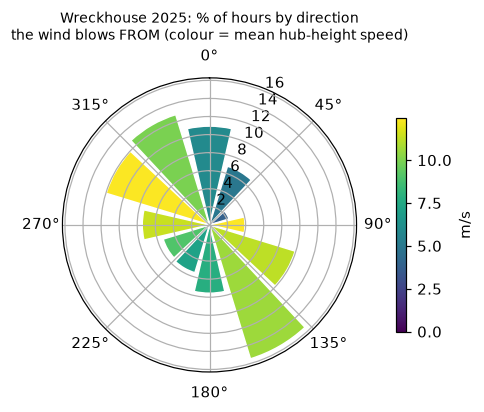

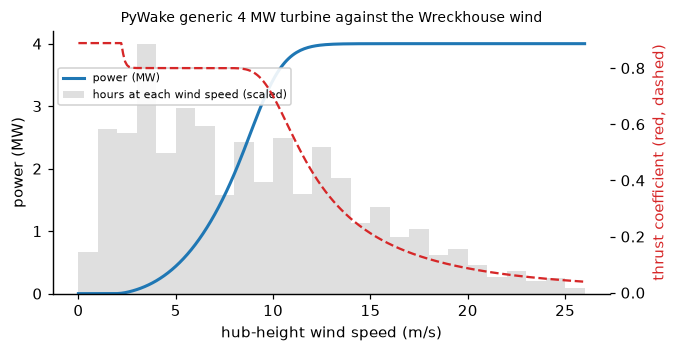

In [2]:
wd, u = ww.load_wind()
raw = pd.read_csv(ww.DATA / "wreckhouse_2025_hourly.csv")
u10 = u / (ww.HUB / 10) ** 0.14
wt = ww.turbine()
p_kw = wt.power(u) / 1e3
print(f"{len(raw)} hourly records in 2025, {len(u)} usable (missing direction or speed dropped)")
print(f"mean speed: {u10.mean():.2f} m/s at 10 m  ->  {u.mean():.2f} m/s at the 110 m hub; calm hours: {(u == 0).mean():.1%}")
print(f"hours at 95%+ of rated power: {(p_kw >= 0.95 * ww.RATED_KW).mean():.0%}  (wakes cost almost nothing then)")

sector = ((wd + 15) % 360 // 30).astype(int)
freq = np.bincount(sector, minlength=12) / len(sector)
mean_speed = np.array([u[sector == s].mean() for s in range(12)])
fig = plt.figure(figsize=(4.6, 4.2))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.bar(np.radians(np.arange(12) * 30), freq * 100, width=np.radians(26),
       color=plt.cm.viridis(mean_speed / mean_speed.max()), edgecolor="white")
ax.set_title("Wreckhouse 2025: % of hours by direction\nthe wind blows FROM (colour = mean hub-height speed)", fontsize=9)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, mean_speed.max()))
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1, label="m/s")
fig.savefig(FIG / "wind_rose.png", bbox_inches="tight"); plt.show()

fig, ax2 = plt.subplots(figsize=(6.4, 3.3))
hist, edges = np.histogram(u, bins=26, range=(0, 26))
ax2.bar(edges[:-1], hist / hist.max() * ww.RATED_KW / 1000, width=1.0, align="edge", color="gray", alpha=0.25,
        label="hours at each wind speed (scaled)")
ws = np.linspace(0, 26, 261)
ax2.plot(ws, wt.power(ws) / 1e6, color="tab:blue", lw=2, label="power (MW)")
ax2.set_xlabel("hub-height wind speed (m/s)"); ax2.set_ylabel("power (MW)")
ax3 = ax2.twinx(); ax3.plot(ws, wt.ct(ws), color="tab:red", lw=1.5, ls="--")
ax3.set_ylabel("thrust coefficient (red, dashed)", color="tab:red"); ax3.spines["top"].set_visible(False)
ax2.legend(fontsize=7, loc="upper left", bbox_to_anchor=(0.0, 0.88), framealpha=0.9)
ax2.set_title("PyWake generic 4 MW turbine against the Wreckhouse wind", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "turbine.png", bbox_inches="tight"); plt.show()

The wind is strongly bimodal: south-easterlies (the Wreckhouse gales) and north-westerlies dominate, so turbines lined up on that axis shade each other most. The wind is also so strong that turbines often run at full power, when a wake costs almost nothing; this is why wake losses here are smaller than at an average site, and our numbers reflect it.

## 3. Classical model and baselines

Two instances on a flat grid with 650 m (5 rotor diameter) spacing:

* **Main instance:** 3 x 4 grid, 12 sites (12 qubits), used for all noiseless experiments.
* **Hardware instance:** 3 x 3 grid, 9 sites (9 qubits), small enough for meaningful results on today's noisy hardware.

In [3]:
spacing = 5 * ww.D
jensen, gaussian = ww.wake_model("jensen"), ww.wake_model("gaussian")
inst = {}
for name, (rows, cols) in {"main_12": (3, 4), "hw_9": (3, 3)}.items():
    xy = ww.grid(rows, cols, spacing)
    lin, W, info = ww.build_qubo(xy, wd, u, model=jensen)
    x_opt, f_opt, values = ww.exact(lin, W)
    x_gr = ww.greedy(lin, W)
    inst[name] = dict(xy=xy, rows=rows, cols=cols, lin=lin, W=W, E=info["E"], cost=info["cost"], x_opt=x_opt,
                      f_opt=f_opt, values=values, f_rand=values.mean(), x_gr=x_gr, f_gr=ww.qubo_values(x_gr, lin, W)[0])

d = inst["main_12"]
E = d["E"]
iu = np.triu_indices(12, 1)
Wm = d["W"][iu]
block_loss = 1 - ww.farm_energy(jensen, d["xy"], wd, u).sum() / (12 * E)
print(f"one turbine alone: E = {E:,.0f} MWh/yr (capacity factor {E / (ww.RATED_KW / 1000 * 8760):.0%})")
print(f"wake couplings (12 sites): {np.count_nonzero(Wm)} of {len(Wm)} pairs, largest {Wm.max():,.0f} MWh/yr "
      f"({Wm.max() / E:.1%} of E), median {np.median(Wm):,.0f}; a full 12-turbine block loses {block_loss:.1%} to wakes")

rows = []
for name, dd in inst.items():
    n = len(dd["lin"])
    rows.append({"instance": name, "sites (qubits)": n, "layouts": 2 ** n,
                 "exact optimum f*": round(dd["f_opt"]), "turbines in optimum": int(dd["x_opt"].sum()),
                 "greedy f": round(dd["f_gr"]), "greedy shortfall (MWh/yr)": round(dd["f_gr"] - dd["f_opt"]),
                 "greedy gap (% of net value)": f"{(dd['f_gr'] - dd['f_opt']) / abs(dd['f_opt']):.1%}",
                 "random mean f": round(dd["f_rand"])})
baseline_table = pd.DataFrame(rows).set_index("instance")
baseline_table

one turbine alone: E = 18,498 MWh/yr (capacity factor 53%)
wake couplings (12 sites): 66 of 66 pairs, largest 344 MWh/yr (1.9% of E), median 90; a full 12-turbine block loses 3.6% to wakes


,sites (qubits),layouts,exact optimum f*,turbines in optimum,greedy f,greedy shortfall (MWh/yr),greedy gap (% of net value),random mean f
instance,,,,,,,,
main_12,12,4096,-9742,10,-9547,195,2.0%,-6657
hw_9,9,512,-8896,8,-8896,0,0.0%,-5854


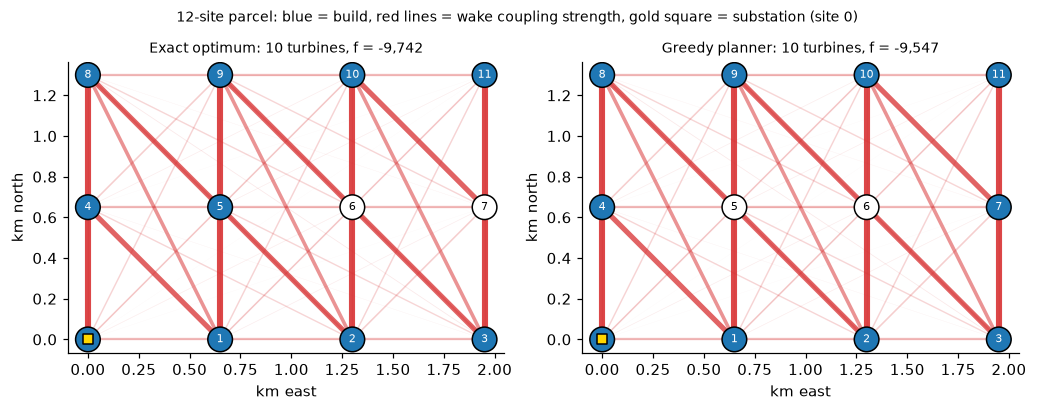

In [4]:
def draw_layout(ax, dd, x, title):
    xy = dd["xy"] / 1000
    W = dd["W"]
    for i, j in zip(*np.triu_indices(len(xy), 1)):
        if W[i, j] > 0:
            ax.plot(*xy[[i, j]].T, color="tab:red", alpha=0.85 * W[i, j] / W.max(), lw=4 * W[i, j] / W.max(), zorder=1)
    ax.scatter(*xy.T, s=260, c=["tab:blue" if b else "white" for b in x], edgecolors="black", zorder=2)
    for k, (px, py) in enumerate(xy):
        ax.annotate(str(k), (px, py), ha="center", va="center", fontsize=7, color="white" if x[k] else "black", zorder=3)
    ax.scatter(*xy[0], marker="s", s=40, c="gold", edgecolors="black", zorder=4)
    ax.set_title(title, fontsize=9); ax.set_aspect("equal"); ax.set_xlabel("km east"); ax.set_ylabel("km north")

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6))
draw_layout(axs[0], d, d["x_opt"], f"Exact optimum: {int(d['x_opt'].sum())} turbines, f = {d['f_opt']:,.0f}")
draw_layout(axs[1], d, d["x_gr"], f"Greedy planner: {int(d['x_gr'].sum())} turbines, f = {d['f_gr']:,.0f}")
fig.suptitle("12-site parcel: blue = build, red lines = wake coupling strength, gold square = substation (site 0)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "layouts.png", bbox_inches="tight"); plt.show()

**Why not just sort or use a greedy rule?** Greedy adds the best site one at a time and never revisits a choice, so it can lock in turbines that later block a better combination. With these realistic Wreckhouse wakes the effect is modest: greedy is optimal on 9 sites and 2% short (in net value) on 12. The interactions are still what make the problem combinatorial, and they are exactly what QAOA encodes.

**Sensitivity to the illustrative cost assumption.** The cost level decides how many turbines are worth building.

In [5]:
sens = []
for frac in [0.85, 0.88, 0.90, 0.92]:
    lin_s, W_s, _ = ww.build_qubo(d["xy"], wd, u, cost_frac=frac, model=jensen)
    xo, fo, _ = ww.exact(lin_s, W_s); xg = ww.greedy(lin_s, W_s); fg = ww.qubo_values(xg, lin_s, W_s)[0]
    sens.append({"base cost (fraction of E)": frac, "turbines in optimum": int(xo.sum()), "f*": round(fo),
                 "greedy shortfall (MWh/yr)": round(fg - fo), "greedy gap": f"{(fg - fo) / abs(fo):.1%}"})
pd.DataFrame(sens).set_index("base cost (fraction of E)")

,turbines in optimum,f*,greedy shortfall (MWh/yr),greedy gap
base cost (fraction of E),,,,
0.85,12,-15709,0,0.0%
0.88,10,-9742,195,2.0%
0.90,9,-6412,157,2.4%
0.92,6,-3768,64,1.7%


## 4. Quantum formulation: from wakes to an Ising Hamiltonian

Substituting $x_i = (1 - z_i)/2$, where $z_i = \pm 1$ is the eigenvalue of Pauli $Z$ on qubit $i$ (so $|0\rangle$ means "no turbine" and $|1\rangle$ means "turbine"), turns the QUBO into

$$H = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j,\qquad h_i = -\tfrac{1}{2}\ell_i - \tfrac{1}{4}\sum_{j} W_{ij},\qquad J_{ij} = \tfrac{1}{4}W_{ij},$$

with $f(x) = \langle x|H|x\rangle + \text{offset}$. The wake physics *is* the $ZZ$ coupling. `test_wakewise.py` checks this identity for every bitstring and confirms Qiskit's bit order (bit $i$ of a measured integer is site $i$).

**Role of the quantum component.** QAOA prepares $|\gamma,\beta\rangle = \prod_{k=1}^{p} e^{-i\beta_k \sum X}\, e^{-i\gamma_k H} |+\rangle^{\otimes n}$: cost layers apply the wake Hamiltonian as phases, mixer layers move amplitude between layouts, and interference concentrates probability on low-energy layouts. A classical optimizer (COBYLA) tunes $(\gamma, \beta)$; the circuit is then sampled and every sampled layout is scored with the full QUBO. We follow the Qiskit pattern: map (QUBO to `SparsePauliOp` and `qaoa_ansatz`), optimize (transpile for the device), execute (Sampler), post-process (score and compare).

**Training objective (CVaR).** A planner needs the *best* layout, not a good average. Instead of minimizing the average energy $\langle H\rangle$, we minimize the average of the best 25% of outcomes (conditional value at risk, CVaR; Barkoutsos et al., *Quantum* 2020), which pushes probability onto the best layouts. Standard training is reported for comparison.

**Why this is an appropriate choice.** The problem is natively quadratic and binary, so there is no encoding overhead and no penalty term; it is NP-hard in general (it contains maximum-weight independent set as a special case); and at 9 to 12 qubits the exact answer is known, so QAOA's quality is measured rather than assumed.

**Metrics.** $P(\text{opt})$: probability that a shot returns an optimal layout. *Gap closed* $= (f_\text{random} - \langle f\rangle_\text{samples}) / (f_\text{random} - f^*)$: 0 means no better than uniform random guessing, 1 means always optimal. $N_{95}$: shots needed to see the optimum at least once with 95% probability, $\ln 0.05 / \ln(1 - P(\text{opt}))$.

Hamiltonian on 12 qubits: 12 Z terms, 66 ZZ terms; |coefficient| max 889.3, offset -6,657.2 MWh/yr
check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts
12-qubit p=1 circuit, gate counts after one decomposition: {'cx': 132, 'rz': 66, 'u': 12, 'p': 12, 'r': 12}


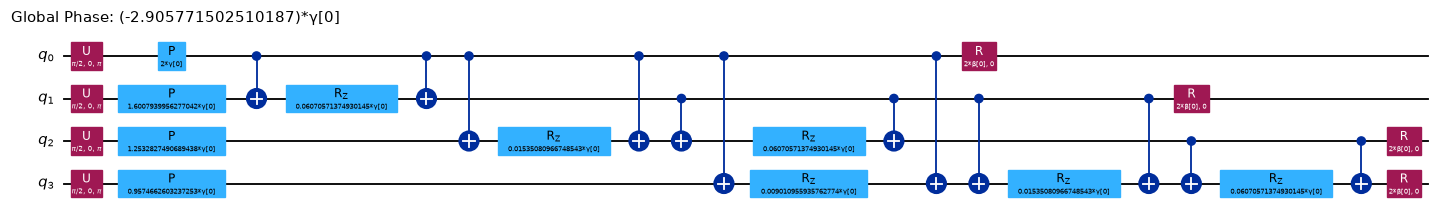

In [6]:
H, offset = ww.qubo_to_ising(d["lin"], d["W"])
scale = np.abs(H.coeffs).max()
Hn = H / scale                      # normalized for training; same minimizer
print(f"Hamiltonian on {H.num_qubits} qubits: {sum(1 for p in H.paulis if str(p).count('Z') == 1)} Z terms, "
      f"{sum(1 for p in H.paulis if str(p).count('Z') == 2)} ZZ terms; |coefficient| max {scale:,.1f}, offset {offset:,.1f} MWh/yr")
diag = H.to_matrix(sparse=True).diagonal().real + offset
assert np.allclose(diag, d["values"]), "Ising energies must equal QUBO values"
print("check passed: <x|H|x> + offset equals the QUBO value for all 4,096 layouts")
print("12-qubit p=1 circuit, gate counts after one decomposition:", dict(ww.qaoa_circuit(Hn, 1).decompose().count_ops()))
H4, _ = ww.qubo_to_ising(d["lin"][:4], d["W"][:4, :4])   # 4-site slice, only to show the circuit structure
ww.qaoa_circuit(H4 / np.abs(H4.coeffs).max(), 1).decompose().draw("mpl", fold=-1, scale=0.6)

## 5. QAOA on the 12-site instance (noiseless simulation)

The $p=1$ energy landscape over $(\gamma, \beta)$ (exact, `StatevectorEstimator`), then circuits of depth $p = 1, 2, 3$ trained with CVaR and with the standard objective, each sampled 10,000 times.

trained p=1 angles (standard objective): gamma = 0.933, beta = 2.460


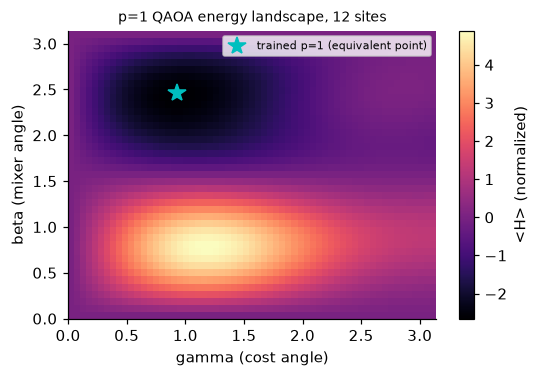

,P(opt),x random,P(opt) within 100 shots,P(sample beats greedy),gap closed,N95 shots
method,,,,,,
uniform random (control),0.02%,1x,2%,0.1%,0.00,"12,269"
QAOA p=1 (CVaR training),2.01%,82x,87%,2.8%,0.73,148
QAOA p=2 (CVaR training),7.40%,303x,100%,8.6%,0.82,39
QAOA p=3 (CVaR training),9.21%,377x,100%,13.4%,0.84,31
QAOA p=1 (standard training),1.87%,77x,85%,,0.77,159
QAOA p=2 (standard training),6.33%,259x,100%,,0.84,46
QAOA p=3 (standard training),8.26%,338x,100%,,0.88,35
greedy planner (one deterministic answer),0.00%,0x,0%,0.0%,0.94,inf


In [7]:
from qiskit.primitives import StatevectorEstimator
ans1 = ww.qaoa_circuit(Hn, 1)                       # parameters ordered [beta, gamma]
gammas, betas = np.linspace(0, np.pi, 61), np.linspace(0, np.pi, 41)   # e^{-i beta sum X} has period pi in beta
grid_params = np.array([[b, g] for b in betas for g in gammas])
landscape = StatevectorEstimator().run([(ans1, Hn, grid_params)]).result()[0].data.evs.reshape(len(betas), len(gammas))

qaoa, standard = {}, {}
for p in [1, 2, 3]:
    ans = ww.qaoa_circuit(Hn, p)
    best, _ = ww.train_qaoa(ans, Hn, starts=5, seed=SEED_STARTS, values=d["values"], alpha=ALPHA)
    counts = ww.ideal_counts(ans, best.x, shots=SHOTS_IDEAL, seed=SEED_SAMPLER)
    qaoa[p] = dict(params=best.x, counts=counts, **ww.summarize(counts, d["lin"], d["W"], d["f_opt"], d["f_rand"]))
    best_e, _ = ww.train_qaoa(ans, Hn, starts=5, seed=SEED_STARTS)
    counts_e = ww.ideal_counts(ans, best_e.x, shots=SHOTS_IDEAL, seed=SEED_SAMPLER)
    standard[p] = dict(params=best_e.x, **ww.summarize(counts_e, d["lin"], d["W"], d["f_opt"], d["f_rand"]))

fig, ax = plt.subplots(figsize=(5.4, 3.4))
im = ax.imshow(landscape, origin="lower", aspect="auto", extent=[0, np.pi, 0, np.pi], cmap="magma")
b1, g1 = standard[1]["params"]
print(f"trained p=1 angles (standard objective): gamma = {g1:.3f}, beta = {b1:.3f}")
if g1 < 0:                      # H is real, so (gamma, beta) and (-gamma, -beta) give the same energy
    g1, b1 = -g1, -b1
if 0 <= g1 <= np.pi:
    ax.plot(g1, b1 % np.pi, "c*", ms=12, label="trained p=1 (equivalent point)")
    ax.legend(fontsize=7, loc="upper right")
ax.set_xlabel("gamma (cost angle)"); ax.set_ylabel("beta (mixer angle)")
fig.colorbar(im, label="<H> (normalized)"); ax.set_title("p=1 QAOA energy landscape, 12 sites", fontsize=9)
fig.savefig(FIG / "landscape.png", bbox_inches="tight"); plt.show()

n_opt_states = int(np.isclose(d["values"], d["f_opt"]).sum())
p_rand = n_opt_states / 2 ** 12
n95 = lambda q: np.log(0.05) / np.log1p(-q) if q > 0 else np.inf
def beats_greedy(counts):
    states = np.array([int(s) for s in counts]); w = np.array(list(counts.values()), float)
    return float(w[d["values"][states] < d["f_gr"] - 1e-9].sum() / w.sum())

rows = [{"method": "uniform random (control)", "P(opt)": p_rand, "x random": 1.0, "P(opt) within 100 shots": 1 - (1 - p_rand) ** 100,
         "P(sample beats greedy)": float((d["values"] < d["f_gr"] - 1e-9).mean()), "gap closed": 0.0, "N95 shots": n95(p_rand)}]
for p, r in qaoa.items():
    rows.append({"method": f"QAOA p={p} (CVaR training)", "P(opt)": r["p_opt"], "x random": r["p_opt"] / p_rand,
                 "P(opt) within 100 shots": 1 - (1 - r["p_opt"]) ** 100, "P(sample beats greedy)": beats_greedy(r["counts"]),
                 "gap closed": r["gap_closed"], "N95 shots": n95(r["p_opt"])})
for p, r in standard.items():
    rows.append({"method": f"QAOA p={p} (standard training)", "P(opt)": r["p_opt"], "x random": r["p_opt"] / p_rand,
                 "P(opt) within 100 shots": 1 - (1 - r["p_opt"]) ** 100, "P(sample beats greedy)": np.nan,
                 "gap closed": r["gap_closed"], "N95 shots": n95(r["p_opt"])})
rows.append({"method": "greedy planner (one deterministic answer)", "P(opt)": 0.0, "x random": 0.0, "P(opt) within 100 shots": 0.0,
             "P(sample beats greedy)": 0.0, "gap closed": (d["f_rand"] - d["f_gr"]) / (d["f_rand"] - d["f_opt"]), "N95 shots": np.inf})
ideal_table = pd.DataFrame(rows).set_index("method")
ideal_table.style.format({"P(opt)": "{:.2%}", "x random": "{:,.0f}x", "P(opt) within 100 shots": "{:.0%}",
                          "P(sample beats greedy)": "{:.1%}", "gap closed": "{:.2f}", "N95 shots": "{:,.0f}"}, na_rep="")

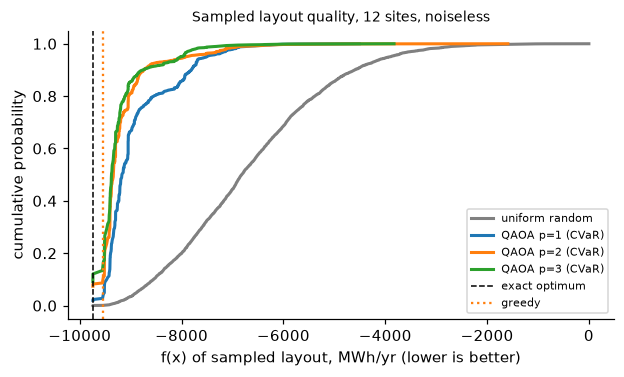

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
v_sorted = np.sort(d["values"])
ax.plot(v_sorted, np.arange(1, len(v_sorted) + 1) / len(v_sorted), color="gray", lw=2, label="uniform random")
for p, r in qaoa.items():
    states = np.array([int(s) for s in r["counts"]]); w = np.array(list(r["counts"].values()), float)
    v = d["values"][states]; o = np.argsort(v)
    ax.plot(v[o], np.cumsum(w[o]) / w.sum(), lw=2, label=f"QAOA p={p} (CVaR)")
ax.axvline(d["f_opt"], color="k", ls="--", lw=1, label="exact optimum")
ax.axvline(d["f_gr"], color="tab:orange", ls=":", lw=1.5, label="greedy")
ax.set_xlabel("f(x) of sampled layout, MWh/yr (lower is better)"); ax.set_ylabel("cumulative probability")
ax.set_title("Sampled layout quality, 12 sites, noiseless", fontsize=9); ax.legend(fontsize=7)
fig.savefig(FIG / "distributions.png", bbox_inches="tight"); plt.show()

## 6. Noise and real hardware: IBM Quantum System One in Quebec

Each $ZZ$ term costs two-qubit gates, and IBM's heavy-hex chips connect each qubit to at most three neighbours, so dense couplings also cost SWAPs. We therefore compare the full Hamiltonian with a **sparsified** one that keeps only couplings at least 25% as strong as the strongest (sampled layouts are still scored with the *full* QUBO, so any harm from sparsifying shows up in the metrics). For each instance (9 sites and 12 sites) we run four circuits:

1. `p1_full`: depth $p=1$, every coupling
2. `p1_sparse`: $p=1$, couplings $\geq 25\%$ of the strongest
3. `p2_sparse`: $p=2$, couplings $\geq 25\%$ of the strongest
4. `control_uniform`: the same ansatz with $\gamma=\beta=0$, which should give uniformly random layouts: a noise-floor check

All are trained in noiseless simulation (no QPU time spent on training), then executed three ways, reported in separate columns: **ideal** statevector simulation; the **IBM Heron r2 noise model** (`FakeFez`, the same processor generation as today's `ibm_quebec`); and **real hardware**, `ibm_quebec` (IBM Quantum System One at PINQ² in Bromont, Quebec, the system provided for this Fall Fest), 4,000 shots per circuit with dynamical decoupling (XY4) and gate twirling.

In [9]:
from qiskit_ibm_runtime.fake_provider import FakeFez
runs = {}
for name, n in [("hw_9", 9), ("main_12", 12)]:
    dd = inst[name]
    # Same function the hardware run uses (`python wakewise.py hardware`), so the circuits are identical.
    circs, names, params = ww.hardware_circuits(dd["lin"], dd["W"], dd["values"], keep=0.25, alpha=ALPHA,
                                                starts=5, seed=SEED_STARTS)
    sc = lambda c, dd=dd: ww.summarize(c, dd["lin"], dd["W"], dd["f_opt"], dd["f_rand"])
    ideal = {nm: sc({s: q for s, q in enumerate(ww.ideal_probabilities(c, []))}) for nm, c in zip(names, circs)}
    model = ww.run_sampler(circs, FakeFez(), shots=SHOTS_DEVICE, seed=SEED_NOISE, names=names,
                           meta=dict(instance=f"{n} sites", params=params), out=ww.RESULTS / f"fake_fez_{n}site.json")
    hw_file = ww.RESULTS / f"hardware_{n}site.json"   # written by `python wakewise.py hardware` or RUN_HARDWARE=1
    if RUN_HARDWARE:
        ww.run_sampler(circs, ww.hardware_backend(), shots=SHOTS_DEVICE, names=names,
                       meta=dict(instance=f"{n} sites", params=params), out=hw_file)
    hw = json.loads(hw_file.read_text()) if hw_file.exists() else None
    if hw:
        assert all(np.allclose(hw["meta"]["params"][k], v) for k, v in params.items()), "hardware circuits differ"
    runs[n] = dict(names=names, params=params, ideal=ideal, model=model, hw=hw, score=sc,
                   p_rand=np.isclose(dd["values"], dd["f_opt"]).sum() / 2 ** n)
    W_sparse = ww.sparsify(dd["W"], 0.25)
    print(f"{n} sites: {np.count_nonzero(np.triu(dd['W'], 1))} couplings, {np.count_nonzero(np.triu(W_sparse, 1))} after sparsifying; "
          f"random guessing finds the optimum in {runs[n]['p_rand']:.2%} of shots")

hardware = runs[9]["hw"] or runs[12]["hw"]
if hardware:
    for n in (9, 12):
        if runs[n]["hw"]:
            print(f"{n}-site job:", json.dumps({k: runs[n]['hw'][k] for k in ['backend', 'job_id', 'utc', 'shots', 'usage_s', 'calibration']}))
else:
    print("No saved hardware results yet: hardware columns below are empty.")
print("Heron r2 noise model (FakeFez) calibration snapshot:", runs[9]["model"]["calibration"])

9 sites: 36 couplings, 23 after sparsifying; random guessing finds the optimum in 0.20% of shots


12 sites: 66 couplings, 34 after sparsifying; random guessing finds the optimum in 0.02% of shots
9-site job: {"backend": "ibm_quebec", "job_id": "dbnl9h0ou4as73b4p1kg", "utc": "2026-11-07T16:42:49Z", "shots": 4000, "usage_s": 7, "calibration": {"two_qubit_gate": "cz", "median_2q_error": 0.0015213620668354938, "median_readout_error": 0.0078125}}
12-site job: {"backend": "ibm_quebec", "job_id": "dbnla58ou4as73b4p2p0", "utc": "2026-11-07T16:43:19Z", "shots": 4000, "usage_s": 7, "calibration": {"two_qubit_gate": "cz", "median_2q_error": 0.0015213620668354938, "median_readout_error": 0.0078125}}
Heron r2 noise model (FakeFez) calibration snapshot: {'two_qubit_gate': 'cz', 'median_2q_error': 0.0039033828523107883, 'median_readout_error': 0.007568359375}


In [10]:
rows = []
for n, r in runs.items():
    for k, nm in enumerate(r["names"]):
        row = {"sites": n, "circuit": nm, "2q gates (Heron model)": r["model"]["circuits"][k]["two_qubit_gates"],
               "ideal P(opt)": r["ideal"][nm]["p_opt"], "ideal gap": r["ideal"][nm]["gap_closed"]}
        s = r["score"](r["model"]["counts"][k])
        row.update({"noise model P(opt)": s["p_opt"], "noise model gap": s["gap_closed"]})
        if r["hw"]:
            s = r["score"](r["hw"]["counts"][k])
            row.update({"hardware 2q gates": r["hw"]["circuits"][k]["two_qubit_gates"], "hardware P(opt)": s["p_opt"],
                        "hardware gap": s["gap_closed"], "hardware x random": s["p_opt"] / r["p_rand"]})
        rows.append(row)
hw_table = pd.DataFrame(rows).set_index(["sites", "circuit"])
fmt = {c: "{:.2%}" for c in hw_table.columns if "P(opt)" in c} | {c: "{:.2f}" for c in hw_table.columns if "gap" in c}
fmt |= {c: "{:,.0f}x" for c in hw_table.columns if "x random" in c}
hw_table.style.format(fmt, na_rep="")

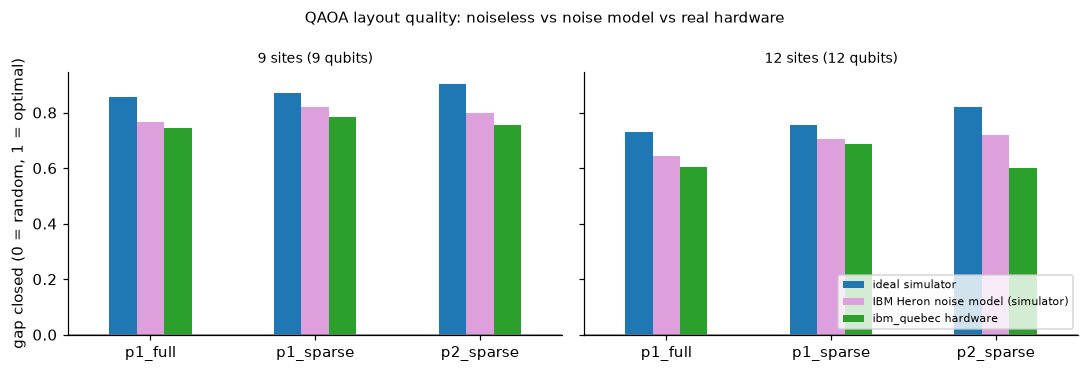

In [11]:
cols = [c for c in ["ideal gap", "noise model gap", "hardware gap"] if c in hw_table.columns]
labels = {"ideal gap": "ideal simulator", "noise model gap": "IBM Heron noise model (simulator)", "hardware gap": "ibm_quebec hardware"}
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, n in zip(axs, (9, 12)):
    t = hw_table.loc[n].loc[runs[n]["names"][:3], cols].rename(columns=labels)
    t.plot.bar(ax=ax, rot=0, color=["tab:blue", "plum", "tab:green"][:len(cols)], legend=(n == 12))
    ax.axhline(0, color="gray", lw=1); ax.set_title(f"{n} sites ({n} qubits)", fontsize=9); ax.set_xlabel("")
axs[0].set_ylabel("gap closed (0 = random, 1 = optimal)")
if len(cols) > 1: axs[1].legend(fontsize=7, loc="lower right")
fig.suptitle("QAOA layout quality: noiseless vs noise model vs real hardware", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "noise_hardware.png", bbox_inches="tight"); plt.show()

## 7. Model check: does the pairwise QUBO rank layouts like a full wind-farm simulation?

The QUBO adds wake losses pair by pair. A full simulation lets every wake act at once (PyWake combines overlapping wakes as a root-sum-square of speed deficits). We also re-score layouts with a different, more modern wake model (Bastankhah and Porte-Agel 2014, Gaussian wakes). If the QUBO ranks layouts the same way, optimizing it is meaningful.

In [12]:
from scipy.stats import spearmanr
order = np.argsort(d["values"])
rng = np.random.default_rng(0)
check = np.unique(np.concatenate([order[:60], rng.choice(4096, 140, replace=False)]))
X = ww.bits(check, 12)
net_pair = -d["values"][check]
net_jensen = np.array([ww.layout_net(x, d["xy"], wd, u, d["cost"], jensen) for x in X])
net_gauss = np.array([ww.layout_net(x, d["xy"], wd, u, d["cost"], gaussian) for x in X])
opt_state = int(np.argmin(d["values"]))
rank = lambda net: int((net > net[check == opt_state][0]).sum()) + 1
rho_j, rho_g = spearmanr(net_pair, net_jensen)[0], spearmanr(net_pair, net_gauss)[0]
print(f"{len(check)} layouts (60 best by QUBO + 140 random)")
print(f"rank correlation with the QUBO: full-farm Jensen {rho_j:.3f}, Gaussian model {rho_g:.3f}")
print(f"the QUBO optimum ranks #{rank(net_jensen)} under full-farm Jensen and #{rank(net_gauss)} under the Gaussian model (of {len(check)})")

farm_mwh = ww.farm_energy(jensen, d["xy"][d["x_opt"] == 1], wd, u).sum()
farm_loss = 1 - farm_mwh / (d["x_opt"].sum() * E)
print(f"optimal {int(d['x_opt'].sum())}-turbine layout: {farm_mwh / 1000:,.0f} GWh/yr with all wakes ({farm_loss:.1%} wake loss), "
      f"about {farm_mwh / HOME_MWH:,.0f} NL homes' electricity")

197 layouts (60 best by QUBO + 140 random)
rank correlation with the QUBO: full-farm Jensen 0.994, Gaussian model 0.997
the QUBO optimum ranks #1 under full-farm Jensen and #1 under the Gaussian model (of 197)
optimal 10-turbine layout: 180 GWh/yr with all wakes (2.8% wake loss), about 10,580 NL homes' electricity


## 8. Results summary and what the evidence supports

In [13]:
d, h = inst["main_12"], inst["hw_9"]
q3 = qaoa[3]
lines = [
    f"Real input: {len(u):,} hours of 2025 Wreckhouse wind; one turbine alone yields {E:,.0f} MWh/yr; "
    f"one neighbour can cost up to {Wm.max():,.0f} MWh/yr ({Wm.max() / E:.1%}); a dense 12-turbine block loses {block_loss:.1%} to wakes.",
    f"Classical: the exact optimum on 12 sites builds {int(d['x_opt'].sum())} turbines; greedy falls short by "
    f"{d['f_gr'] - d['f_opt']:,.0f} MWh/yr ({(d['f_gr'] - d['f_opt']) / abs(d['f_opt']):.1%} of net value); on 9 sites greedy is optimal.",
    "Quantum (noiseless, 12 qubits, CVaR training): " + "; ".join(
        f"p={p}: P(opt) {r['p_opt']:.2%} ({r['p_opt'] / p_rand:.0f}x random), gap closed {r['gap_closed']:.2f}"
        for p, r in qaoa.items()) + f". Shots to see the optimum with 95% confidence: {n95(q3['p_opt']):,.0f} (p=3) vs {n95(p_rand):,.0f} (random). "
    f"Standard training at p=3: P(opt) {standard[3]['p_opt']:.2%}.",
]
for n, r in runs.items():
    t = hw_table.loc[n]
    lines.append(f"Noise model, {n} qubits: " + "; ".join(
        f"{nm}: gap closed {t.loc[nm, 'ideal gap']:.2f} ideal -> {t.loc[nm, 'noise model gap']:.2f} noisy" for nm in r["names"][:3]) + ".")
    if r["hw"]:
        lines.append(f"Hardware, {n} qubits ({r['hw']['backend']}, job {r['hw']['job_id']}): " + "; ".join(
            f"{nm}: P(opt) {t.loc[nm, 'hardware P(opt)']:.2%} ({t.loc[nm, 'hardware x random']:.0f}x random), gap closed {t.loc[nm, 'hardware gap']:.2f}"
            for nm in r["names"][:3]) + f"; control gap closed {t.loc['control_uniform', 'hardware gap']:.2f}.")
lines.append(f"Model check: pairwise QUBO vs full-farm Jensen rank correlation {rho_j:.3f}, vs Gaussian model {rho_g:.3f}; "
             f"QUBO optimum ranks #{rank(net_jensen)} and #{rank(net_gauss)}.")
print("\n".join("- " + s for s in lines))

# Single source of truth for the slides: every number quoted in the deck comes from this file.
fl = lambda v: None if v is None or (isinstance(v, float) and not np.isfinite(v)) else float(v)
summary = dict(
    hours=len(u), mean_hub_ms=fl(u.mean()), E=fl(E), capacity_factor=fl(E / (ww.RATED_KW / 1000 * 8760)),
    full_power_share=fl((p_kw >= 0.95 * ww.RATED_KW).mean()), block_loss=fl(block_loss),
    max_pair_loss=fl(Wm.max()), max_pair_loss_frac=fl(Wm.max() / E),
    spearman_jensen=fl(rho_j), spearman_gauss=fl(rho_g), rank_jensen=rank(net_jensen), rank_gauss=rank(net_gauss),
    farm_mwh=fl(farm_mwh), farm_loss=fl(farm_loss), homes=fl(farm_mwh / HOME_MWH), home_mwh=HOME_MWH,
    main=dict(sites=12, f_opt=fl(d["f_opt"]), turbines=int(d["x_opt"].sum()), f_greedy=fl(d["f_gr"]),
              greedy_shortfall=fl(d["f_gr"] - d["f_opt"]), greedy_gap=fl((d["f_gr"] - d["f_opt"]) / abs(d["f_opt"])),
              f_random=fl(d["f_rand"]), greedy_gap_closed=fl(ideal_table.iloc[-1]["gap closed"])),
    hw9=dict(sites=9, f_opt=fl(h["f_opt"]), turbines=int(h["x_opt"].sum()),
             greedy_gap=fl((h["f_gr"] - h["f_opt"]) / abs(h["f_opt"])), p_opt_random=fl(runs[9]["p_rand"])),
    sensitivity=sens,
    random=dict(p_opt=fl(p_rand), n95=fl(n95(p_rand)), within100=fl(1 - (1 - p_rand) ** 100)),
    qaoa={str(p): dict(p_opt=fl(r["p_opt"]), gap_closed=fl(r["gap_closed"]), n95=fl(n95(r["p_opt"])),
                       within100=fl(1 - (1 - r["p_opt"]) ** 100), beats_greedy=fl(beats_greedy(r["counts"])))
          for p, r in qaoa.items()},
    standard={str(p): dict(p_opt=fl(r["p_opt"]), gap_closed=fl(r["gap_closed"])) for p, r in standard.items()},
    devices={str(n): {nm: {k: fl(v) for k, v in hw_table.loc[n].loc[nm].items()} for nm in r["names"]} for n, r in runs.items()},
    p_rand={str(n): fl(r["p_rand"]) for n, r in runs.items()},
    noise_model=dict(name="fake_fez", calibration=runs[9]["model"]["calibration"]),
    hardware={str(n): ({k: r["hw"][k] for k in ["backend", "job_id", "utc", "shots", "usage_s", "calibration"]} if r["hw"] else None)
              for n, r in runs.items()},
    validation=dict(pairwise=np.round(net_pair).tolist(), full_jensen=np.round(net_jensen).tolist(), gaussian=np.round(net_gauss).tolist()),
)
(ww.RESULTS / "summary.json").write_text(json.dumps(summary, indent=1))
print("saved results/summary.json")

- Real input: 8,740 hours of 2025 Wreckhouse wind; one turbine alone yields 18,498 MWh/yr; one neighbour can cost up to 344 MWh/yr (1.9%); a dense 12-turbine block loses 3.6% to wakes.
- Classical: the exact optimum on 12 sites builds 10 turbines; greedy falls short by 195 MWh/yr (2.0% of net value); on 9 sites greedy is optimal.
- Quantum (noiseless, 12 qubits, CVaR training): p=1: P(opt) 2.01% (82x random), gap closed 0.73; p=2: P(opt) 7.40% (303x random), gap closed 0.82; p=3: P(opt) 9.21% (377x random), gap closed 0.84. Shots to see the optimum with 95% confidence: 31 (p=3) vs 12,269 (random). Standard training at p=3: P(opt) 8.26%.
- Noise model, 9 qubits: p1_full: gap closed 0.86 ideal -> 0.77 noisy; p1_sparse: gap closed 0.87 ideal -> 0.82 noisy; p2_sparse: gap closed 0.90 ideal -> 0.80 noisy.
- Hardware, 9 qubits (ibm_quebec, job dbnl9h0ou4as73b4p1kg): p1_full: P(opt) 5.22% (27x random), gap closed 0.74; p1_sparse: P(opt) 5.45% (28x random), gap closed 0.78; p2_sparse: P(opt) 1

**What the evidence supports**

* The siting problem is genuinely combinatorial on real NL wind, but with realistic Wreckhouse wakes its stakes at this size are modest: greedy is optimal on 9 sites and about 2% short on 12. Wakes cost less here than at an average site because turbines often run at full power.
* QAOA, implemented with Qiskit, turns the wake Hamiltonian into a sampler strongly biased toward good layouts: in noiseless simulation the optimal layout appears hundreds of times more often than under random guessing, quality improves with depth $p$, and CVaR training adds to it.
* On real IBM hardware (`ibm_quebec`) the signal is weaker than in noiseless simulation but clearly survives at 9 and 12 qubits, up to 68 times random guessing on 12 qubits; the noise model predicts the hardware behaviour well. Dropping weak couplings cuts two-qubit gates by about 40% and gave the best depth-1 results on hardware.
* The pairwise QUBO ranks layouts almost exactly like full PyWake simulations, including a different (Gaussian) wake model, so optimizing it is meaningful.
* What it does **not** support: any claim of quantum advantage. A laptop enumerates every layout here, and greedy is near-optimal. These results are a verified proof of concept of the pipeline and its behaviour, within the tested conditions (one wind year, idealized flat parcel, illustrative costs).

## 9. Limitations, assumptions, resources and next steps

* **Model:** flat terrain, one wind year, 10 m data extrapolated to hub height, a generic 4 MW turbine, and costs expressed as energy are simplifications. PyWake models are engineering models, not field measurements.
* **Quantum:** QAOA depth $p \le 3$, trained in noiseless simulation; dense couplings need many SWAPs on heavy-hex connectivity, which is why hardware circuits use depth 1 to 2 and why we sparsify.
* **Resources:** each noiseless experiment takes seconds on a laptop; the full notebook runs in a few minutes. Hardware: two jobs (9 and 12 qubits) of 4 circuits x 4,000 shots on `ibm_quebec`; QPU usage is recorded in `results/hardware_*.json`.
* **Next steps:** a real Codroy Valley parcel with terrain-aware wind; spacing and exclusion constraints (wetlands, caribou habitat) as extra QUBO terms; constraint-preserving mixers and warm starts; larger instances where exact enumeration is impossible and QAOA must be compared with strong classical heuristics (simulated annealing, MILP). A natural home is MUN's CREATE-SWIFT program, with Mitacs Accelerate as a route to an industry partner.

## 10. Credits and team contribution

* **Reused and adapted:** the QAOA workflow pattern (QUBO -> Ising -> ansatz -> optimizer -> Sampler) from Tinh Bui's *Quantum Optimization* workshop notebook (Qiskit Fall Fest 2026), whose brute-force answer selection we deliberately replace with selection from samples; IBM runtime setup and Sampler options from the *Qiskit 101* hands-on notebook (IBM, Apache 2.0) and the Fall Fest IBM hardware example (credential names `apikey` and `crn`, channel `ibm_quantum_platform`); Qiskit, Qiskit Aer, Qiskit IBM Runtime (Apache 2.0); DTU PyWake (MIT licence; Pedersen et al., DTU Wind Energy); NumPy, SciPy, pandas, Matplotlib.
* **Data:** Environment and Climate Change Canada hourly climate data (Open Government Licence, Canada); NL household electricity use from the NL Government (2026 release on the electricity rebate: about 1,400 to 1,500 kWh per month).
* **Methods from the literature:** Jensen (1983) and Katic, Højstrup and Jensen (1986) wake model; Bastankhah and Porte-Agel (2014) Gaussian wake model; Mosetti, Poloni and Diviacco (1994) grid-based layout optimization; Farhi, Goldstone and Gutmann (2014) QAOA; Barkoutsos et al. (2020) CVaR objective; prior QUBO formulations of wind-farm layout (e.g., Senderovich et al., 2022).
* **Our contribution:** the problem framing for NL's west coast, the QUBO built from real Wreckhouse wind and PyWake pair simulations, the validation design (exact, greedy and random baselines on the same instances, full-farm and Gaussian model checks, sparsification study, noise model and real-hardware runs, control circuit), all code in `wakewise.py`, the tests, and the experiments and their interpretation. AI tools (Claude) assisted with code and writing; the team reviewed and can explain every part.